We can adapt equation 3. Note that we are assuming the same lattice constant in both directions, and that $t_\pm = t'(1\pm \delta)$

Also, the convention being used here is that spin up is $s=0$ and spin down is $s=1$ such that $(-1)^s$ varies appropriately.

In [119]:
import numpy as np


def H_s(k, a1, a2, s, t, a, tminus, tplus, U, dm):
    """
    Diagonal block from HFA Hamiltonian in Eq. 3.

    Args:
        k (2x1 vector): momentum vector
        a1 (2x1 vector): first lattice vector
        a2 (2x1 vector): second lattice vector
        s (int): spin of this block
        t (float): nn hopping integral
        a (float): lattice constant
        tminus (float): hopping integral in the a1 direction
        tplus (float): hopping integral in the a2 direction
        U (float): on-site Hubbard interaction
        dm (float): altermagnetic order parameter

    Returns: 
        2x2 numpy array: diagonal block of the Hamiltonian for spin s
    """
    hAAs = -2 * tminus * np.cos(np.dot(k, a1)) - 2 * tplus * np.cos(np.dot(k, a2)) - (-1)**s * U * dm
    hBBs = -2 * tplus * np.cos(np.dot(k, a1)) - 2 * tminus * np.cos(np.dot(k, a2)) + (-1)**s * U * dm
    hABs = -2 * t * (np.cos(k[0] * a) + np.cos(k[1] * a))
    hBAs = np.conjugate(hABs) # complex conj. but it's real so it'll just output the same thing

    return np.array([[hAAs, hABs], [hBAs, hBBs]])

# def fermi_dist(epsilon, mu, beta):
#     """
#     Fermi-Dirac distribution, returns average number at state with epsilon, with chemical potential mu

#     ARgs:
#         epsilon (float): energy of state
#         mu (float): chemical potential of state
#         beta (float): k_B * T

#     Returns:
#        float: average number at state
#     """
#     return 1 / (np.exp(beta * (epsilon - mu)) + 1)

def fermi_dist(epsilon, mu):
    """
    Fermi-Dirac distribution, returns average number at state with epsilon, with chemical potential mu
    Seeing as we're doing a low temperature calculation, we may as well just use the Heaviside function

    ARgs:
        epsilon (float): energy of state
        mu (float): chemical potential of state
        beta (float): k_B * T

    Returns:
       float: average number at state
    """
    return 1.0 if epsilon < mu else 0.0

def self_consistency_dm(k_list, N, a1, a2, t, a, tminus, tplus, U, dm_in, mu):
    """
    Using equation (S2), we go through every element in the k_list to get the altermagnetic order parameter dm

    Args:
        k_list (nxn numpy array): grid of momenta
        N: number of sites
        a1 (2x1 vector): first lattice vector
        a2 (2x1 vector): second lattice vector
        s_list (int list): spins of each block
        t (float): nn hopping integral
        a (float): lattice constant
        tminus (float): hopping integral in the a1 direction
        tplus (float): hopping integral in the a2 direction
        U (float): on-site Hubbard interaction
        dm_in (float): input altermagnetic order parameter
        mu (float): chemical potential

    Returns:
        float: output altermagnetic order parameter dm
    """

    dm_out = 0

    for k in k_list:
        H_up = H_s(k, a1, a2, 0, t, a, tminus, tplus, U, dm_in)
        epsilons, psis = np.linalg.eigh(H_up)
        for epsilon, psi in zip(epsilons, psis.T):
            # print(epsilon, psi)
            dm_out += (np.abs(psi[0]) ** 2 - np.abs(psi[1]) ** 2) * fermi_dist(epsilon, mu) # each term in sum (upper left block)        

        H_down = H_s(k, a1, a2, 1, t, a, tminus, tplus, U, dm_in)
        epsilons, psis = np.linalg.eigh(H_down)
        for epsilon, psi in zip(epsilons, psis.T):
            # print(epsilon, psi)
            dm_out += (np.abs(psi[1]) ** 2 - np.abs(psi[0]) ** 2) * fermi_dist(epsilon, mu) # each term in sum (lower right block)        
        
    return dm_out / (4 * N)

def self_consistency_mu(k_list, N, a1, a2, t, a, tminus, tplus, U, dm_in, mu):
    """
    Using equation (S3), we go through every element in the k_list to get the average number of electrons n

    Args:
        k_list (nxn numpy array): grid of momenta
        N (int): number of sites
        mu (float): chemical potential

    Returns:
        float: average number of electrons n
    """

    n = 0
    
    for k in k_list:
        H_up = H_s(k, a1, a2, 0, t, a, tminus, tplus, U, dm_in)
        epsilons, psis = np.linalg.eigh(H_up)
        for epsilon, psi in zip(epsilons, psis.T):
            n += fermi_dist(epsilon, mu) # each term in sum (upper left block)        

        H_down = H_s(k, a1, a2, 1, t, a, tminus, tplus, U, dm_in)
        epsilons, psis = np.linalg.eigh(H_down)
        for epsilon, psi in zip(epsilons, psis.T):
            n += fermi_dist(epsilon, mu) # each term in sum (lower right block)        
        
    return n / (2 * N)

    

def t_plusminus(tp, delta):
    """
    Calculate tplus and tminus based on tp and delta

    Args:
        tp (float): hopping integral
        delta (float): parameter for hopping

    Returns:
        tuple: (tplus, tminus)
    """
    tplus = tp * (1 + delta)
    tminus = tp * (1 - delta)
    return tplus, tminus


# Parameters

In [120]:
a = 1
k = np.array([1, 1])
a1 = np.array([a, a])
a2 = np.array([a, -a])
tp = 0.3
t = 1.0
delta = 0.9
tplus, tminus = t_plusminus(tp, delta)
U = 3.5
dm_in = 0.1
N=200*200
mu = 0.0


The unit cell has lattice vectors $a_1 = (a, a), a_2 = (a, -a)$, so we get RLVs:

$$
a_1 \cdot b_1 = 2\pi \\
a_2 \cdot b_1 = 0
$$

and

$$
a_1 \cdot b_2 = 0 \\
a_2 \cdot b_2 = 2\pi
$$

which is fulfilled by 

$$
b_1 = \left( \frac \pi a,\frac  \pi a\right)
$$

$$
b_2 = \left(\frac \pi a, -\frac \pi a\right)
$$

To construct our meshgrid in reciprocal space, we need to fill the diamond between $(\pi/a, \pi/a), (\pi/a, -\pi/a), (-\pi/a, \pi/a), (-\pi/a, -\pi/a)$. The easiest way to do that is to construct a unit square, then map each unit square into the RLV basis (each unit square value becomes a component in the RLV basis) and finally scale it by $\pi/a$.

We also don't want to include the edges twice so we can take $N_x+1$ or $N_y+1$ points and ignore the last one for each axis.

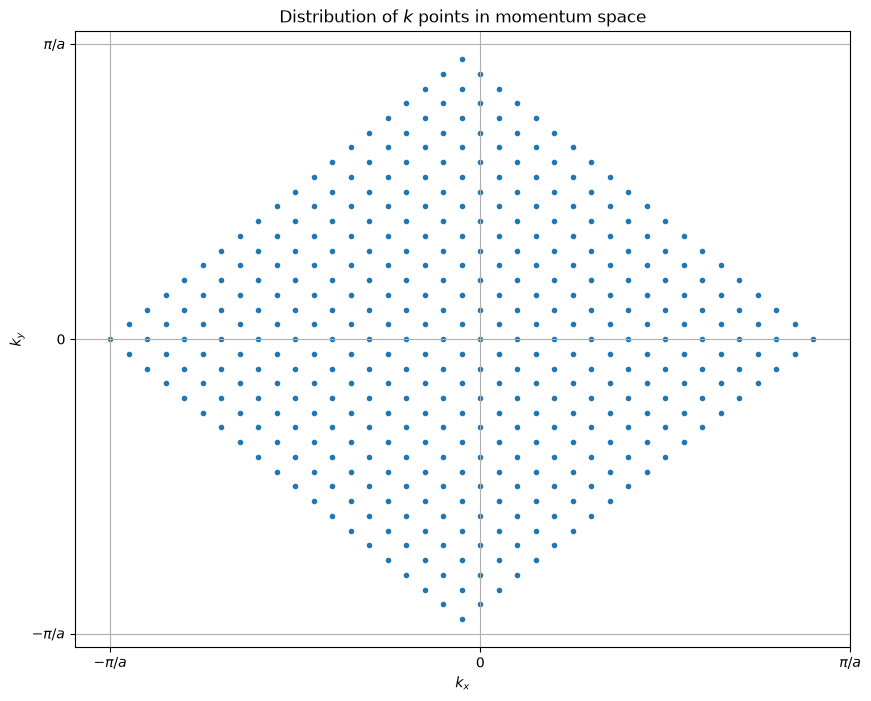

In [121]:
import matplotlib.pyplot as plt
N_x = 20
N_y = 20 # not strictly in x and y directions apart from in the unit square...
# construct a unit square
unit_x, unit_y = np.meshgrid(np.linspace(-1/2, 1/2, N_x+1)[:-1], np.linspace(-1/2, 1/2, N_y+1)[:-1]) # we do NOT want to repeat the endpoints
k_list_x = np.pi / a * (unit_x + unit_y)
k_list_y = np.pi / a * (unit_x - unit_y)

fig = plt.figure(figsize=(10,8))
ticks = [-np.pi / a, 0, np.pi / a]
labels = [r'$-\pi/a$', '0', r'$\pi/a$']
plt.scatter(k_list_x, k_list_y, marker=".")
plt.title(r"Distribution of $k$ points in momentum space")
plt.grid(True)
plt.xticks(ticks, labels)
plt.yticks(ticks, labels)
plt.xlabel(r"$k_x$")
plt.ylabel(r"$k_y$")
plt.show()


In [122]:
N_x = 200
N_y = 200 # not strictly in x and y directions apart from in the unit square...
# construct a unit square
unit_x, unit_y = np.meshgrid(np.linspace(-1/2, 1/2, N_x+1)[:-1], np.linspace(-1/2, 1/2, N_y+1)[:-1]) # we do NOT want to repeat the endpoints
k_list_x = np.pi / a * (unit_x + unit_y)
k_list_y = np.pi / a * (unit_x - unit_y)

# Testing

The paper uses "$t'/t=0.3$, $\delta = 0.9$, and $U/t=3.5$"

We iterate by first choosing a value for $\delta m$, then plug it into

In [123]:
k_list = list(zip(k_list_x.flatten(), k_list_y.flatten()))

# for x, y in k_list:
#     print(x, y)

H1 = H_s(k, a1, a2, 0, t, a, tminus, tplus, U, dm_in)
H2 = H_s(k, a1, a2, 1, t, a, tminus, tplus, U, dm_in)
# print(H1)
H = np.block([[H1,                  np.zeros((2,2))], 
              [np.zeros((2,2)),     H2]])
print(H)
epsilons, psis = np.linalg.eig(H)
psis_matrix = np.array(psis)
print(epsilons)
print(psis)

[[-1.46503119 -2.16120922  0.          0.        ]
 [-2.16120922  0.76440739  0.          0.        ]
 [ 0.          0.         -0.76503119 -2.16120922]
 [ 0.          0.         -2.16120922  0.06440739]]
[-2.78206526+0.j  2.08144146+0.j -2.55095212+0.j  1.85032833+0.j]
[[-0.85393251+0.j  0.52038377+0.j  0.        +0.j  0.        +0.j]
 [-0.52038377+0.j -0.85393251+0.j  0.        +0.j  0.        +0.j]
 [ 0.        +0.j  0.        +0.j -0.77086118+0.j  0.63700317+0.j]
 [ 0.        +0.j  0.        +0.j -0.63700317+0.j -0.77086118+0.j]]


In [124]:
# mu_old = mu
# mu_new = mu

# while()

self_consistency_mu(k_list, N, a1, a2, t, a, tminus, tplus, U, dm_in, 0.88)

1.042275

# TODO: just set mu to fermi energy, we don't need this whole rigamarole with root finding :)

In [125]:
k_list_x, k_list_y = np.meshgrid(np.linspace(-np.pi/a, np.pi/a, 200), np.linspace(-np.pi/a, np.pi/a, 200))
k_list = list(zip(k_list_x.flatten(), k_list_y.flatten()))

self_consistency_dm(k_list, N, a1, a2, t, a, tminus, tplus, U, 1.0, mu)


np.float64(0.4431522505611794)